# GNSS under the sky: real satellites, DOP, terrain and Bpv heights

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/gnss_sky_en.ipynb)

**OpenSkyLab · notebook for the visual** [GNSS under the sky](https://openskylab.space/edu_viz_gnss_sky.html) · [česká verze](gnss_sky_cs.ipynb)

The visual shows how the number and layout of satellites set the DOP, what obstacles and the elevation mask do and why GNSS height is less accurate than position. Here you compute the positions of real GPS, Galileo, GLONASS and BeiDou satellites from current orbits, the real horizon in the Vltava valley from the ČÚZK terrain model, and the conversion from ellipsoidal height to Bpv height from survey control points.

**Goal:** draw the real GNSS sky over Suchdol, compute HDOP, VDOP and PDOP over a day, assess the effect of a forest and a deep valley, find the nearest CZEPOS reference station and convert an RTK height to Bpv.

**Data:** current orbital elements (TLE) of the GNSS group from CelesTrak; DMR 5G (ČÚZK) for the valley horizon; CZEPOS network stations and densification survey points with both Bpv height and ETRS89 ellipsoidal height from the ČÚZK BodovaPole service.

**Tasks:** four. Write your answers in the *Your answer* cells below the tasks. Lines marked `# ◀ parameter` are meant to be changed; run the cell again with Shift + Enter.

**Time:** about 50 min. You need a Google account (Colab); nothing is installed on your computer. Run the cells in order from top to bottom.

## 1. Setup and satellite orbits

In [1]:
%pip install -q sgp4 rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, time, requests
from datetime import datetime, timedelta, timezone
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import rasterio
from pyproj import Transformer
from sgp4.api import Satrec, jday

def cuzk_raster(service, x0, y0, x1, y1, res=2.0):
    """Window of a ČÚZK raster (dmr5g, dmp1g, dmp_obrazova_korelace) in S-JTSK (EPSG:5514), heights in Bpv.
    Returns the height array (row 0 = north) and its transform."""
    nx, ny = int(round((x1 - x0) / res)), int(round((y1 - y0) / res))
    url = f"https://ags.cuzk.cz/arcgis2/rest/services/{service}/ImageServer/exportImage"
    params = {"bbox": f"{x0},{y0},{x1},{y1}", "bboxSR": 5514, "imageSR": 5514, "size": f"{nx},{ny}",
              "format": "tiff", "pixelType": "F32", "interpolation": "RSP_BilinearInterpolation", "f": "image"}
    for attempt in range(4):
        r = requests.get(url, params=params, timeout=120)
        if r.ok and r.headers.get("content-type", "").startswith("image"):
            break
        time.sleep(3 * (attempt + 1))
    r.raise_for_status()
    with rasterio.MemoryFile(r.content) as mem, mem.open() as ds:
        return ds.read(1).astype(float), ds.transform

TLE_FILE = "gnss.tle"                       # CelesTrak updates the data every 2 h and limits repeated downloads, so we reuse the downloaded file
if os.path.exists(TLE_FILE) and time.time() - os.path.getmtime(TLE_FILE) < 2 * 3600:
    tle = open(TLE_FILE).read()
else:
    tle = None
    for attempt in range(6):
        try:
            r = requests.get("https://celestrak.org/NORAD/elements/gp.php", params={"GROUP": "gnss", "FORMAT": "tle"}, timeout=60)
            if r.ok and r.text.count("\n1 ") > 50:
                tle = r.text; open(TLE_FILE, "w").write(tle); break
            print("CelesTrak:", r.status_code, "– retrying")
        except requests.RequestException as e:
            print("CelesTrak:", type(e).__name__, "– retrying")
        time.sleep(5 * (attempt + 1))
    if tle is None:
        raise RuntimeError("CelesTrak does not respond. Wait a few minutes and run the cell again; "
                       "CelesTrak temporarily refuses connections after repeated downloads in a short time.")
lines = [l.rstrip() for l in tle.splitlines() if l.strip()]

def system(name):
    if name.startswith("GPS"): return "GPS"
    if name.startswith("GSAT0"): return "Galileo"
    if name.startswith("COSMOS"): return "GLONASS"
    if name.startswith("BEIDOU"): return "BeiDou"
    return None
SATS = [(lines[i].strip(), system(lines[i]), Satrec.twoline2rv(lines[i + 1], lines[i + 2])) for i in range(0, len(lines) - 2, 3)]
SATS = [s for s in SATS if s[1]]
print(pd.Series([s[1] for s in SATS]).value_counts().to_string())

BeiDou     53
GPS        32
Galileo    32
GLONASS    26


2026-10-29 07:26 UTC: 41 satellites above the 10° mask: {'BeiDou': 14, 'Galileo': 10, 'GLONASS': 9, 'GPS': 8}


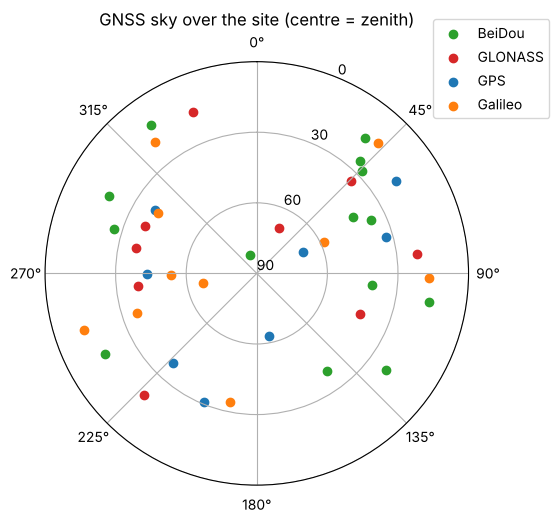

In [3]:
A, F = 6378137.0, 1 / 298.257223563
def ecef(lat, lon, h):
    la, lo = np.radians(lat), np.radians(lon); e2 = F * (2 - F); N = A / np.sqrt(1 - e2 * np.sin(la) ** 2)
    return np.array([(N + h) * np.cos(la) * np.cos(lo), (N + h) * np.cos(la) * np.sin(lo), (N * (1 - e2) + h) * np.sin(la)])

def az_el(t_utc, lat, lon, h=300.0):
    """Azimuth and elevation (°) of all satellites at time t_utc for site lat, lon, h (ellipsoidal height)."""
    jd, fr = jday(t_utc.year, t_utc.month, t_utc.day, t_utc.hour, t_utc.minute, t_utc.second)
    gmst = np.radians((280.46061837 + 360.98564736629 * (jd + fr - 2451545.0)) % 360)
    R = np.array([[np.cos(gmst), np.sin(gmst), 0], [-np.sin(gmst), np.cos(gmst), 0], [0, 0, 1]])  # TEME → ECEF (no polar motion)
    la, lo = np.radians(lat), np.radians(lon)
    enu = np.array([[-np.sin(lo), np.cos(lo), 0],
                    [-np.sin(la) * np.cos(lo), -np.sin(la) * np.sin(lo), np.cos(la)],
                    [np.cos(la) * np.cos(lo), np.cos(la) * np.sin(lo), np.sin(la)]])
    site = ecef(lat, lon, h)
    rows = []
    for name, sysname, sat in SATS:
        e, r_, _ = sat.sgp4(jd, fr)
        if e: continue
        d = enu @ (R @ (np.array(r_) * 1000) - site)
        rows.append((name, sysname, np.degrees(np.arctan2(d[0], d[1])) % 360, np.degrees(np.arcsin(d[2] / np.linalg.norm(d)))))
    return pd.DataFrame(rows, columns=["satellite", "system", "az", "el"])

LAT, LON = 50.130, 14.373          # ◀ parameter: site (Suchdol campus)
now = datetime.now(timezone.utc).replace(second=0, microsecond=0)
sky = az_el(now, LAT, LON)
mask = 10                          # ◀ parameter: elevation mask (°)
vis = sky[sky.el > mask]
print(f"{now:%Y-%m-%d %H:%M} UTC: {len(vis)} satellites above the {mask}° mask:", vis.system.value_counts().to_dict())
COL = {"GPS": "tab:blue", "Galileo": "tab:orange", "GLONASS": "tab:red", "BeiDou": "tab:green"}
fig = plt.figure(figsize=(5.5, 5.5)); ax = fig.add_subplot(projection="polar")
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1); ax.set_rlim(90, 0); ax.set_rticks([0, 30, 60, 90])
for s, g in vis.groupby("system"):
    ax.scatter(np.radians(g.az), g.el, c=COL[s], label=s)
ax.legend(loc="lower left", bbox_to_anchor=(0.9, 0.85)); ax.set_title("GNSS sky over the site (centre = zenith)"); plt.show()

## 2. DOP over a day

We compute DOP from geometry: each satellite gives a row of the matrix G with the unit direction vector (east, north, up) and a one for the receiver clock (each system has its own clock offset). Q = (GᵀG)⁻¹, HDOP = √(Q_EE + Q_NN), VDOP = √Q_UU, PDOP = √(Q_EE + Q_NN + Q_UU).

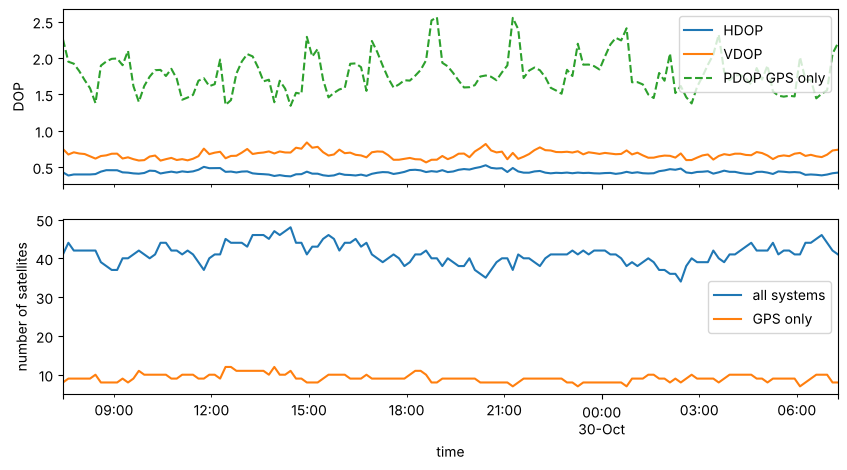

     HDOP  VDOP  PDOP  satellites
min  0.37  0.56  0.71        34.0
50%  0.43  0.67  0.80        41.0
max  0.53  0.84  0.97        48.0


In [4]:
def dop(df, systems=("GPS", "Galileo", "GLONASS", "BeiDou")):
    df = df[df.system.isin(systems)]
    if len(df) < 4 + df.system.nunique() - 1:
        return np.nan, np.nan, np.nan, len(df)
    az, el = np.radians(df.az.values), np.radians(df.el.values)
    G = np.c_[-np.cos(el) * np.sin(az), -np.cos(el) * np.cos(az), -np.sin(el)]
    G = np.c_[G, pd.get_dummies(df.system).values.astype(float)]
    Q = np.linalg.inv(G.T @ G)
    return np.sqrt(Q[0, 0] + Q[1, 1]), np.sqrt(Q[2, 2]), np.sqrt(Q[0, 0] + Q[1, 1] + Q[2, 2]), len(df)

def day_series(horizon=lambda az: np.full_like(az, mask, dtype=float), systems=("GPS", "Galileo", "GLONASS", "BeiDou"), lat=LAT, lon=LON, step=10):
    out = []
    for k in range(0, 24 * 60, step):
        tt = now + timedelta(minutes=k)
        s = az_el(tt, lat, lon)
        s = s[s.el > horizon(s.az.values)]
        out.append((tt, *dop(s, systems)))
    return pd.DataFrame(out, columns=["time", "HDOP", "VDOP", "PDOP", "satellites"]).set_index("time")

open_sky = day_series()
gps_only = day_series(systems=("GPS",))
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
open_sky[["HDOP", "VDOP"]].plot(ax=ax[0]); gps_only[["PDOP"]].rename(columns={"PDOP": "PDOP GPS only"}).plot(ax=ax[0], ls="--")
open_sky["satellites"].plot(ax=ax[1], label="all systems"); gps_only["satellites"].plot(ax=ax[1], label="GPS only"); ax[1].legend()
ax[0].set_ylabel("DOP"); ax[1].set_ylabel("number of satellites"); plt.show()
print(open_sky.describe().loc[["min", "50%", "max"]].round(2))

> **✏️ Task 1.** Why is VDOP larger than HDOP all day? Explain it by where the satellites are in the sky and where they cannot be. How many satellites does a four-system receiver see and how many with GPS only, and how does that affect PDOP? Set the mask to 20° and then 5°.

*Your answer:* 

## 3. Forest to the south or to the north?

A forest edge blocks the sky up to about 35° on one side. The orbits of GPS (inclination 55°) and Galileo (56°) never go beyond 55–56° latitude, so in central Europe there is a region without satellites in the northern sky at medium elevations. Low above the northern horizon, however, we see satellites passing “beyond the pole”. Which side of the forest hurts more is therefore not obvious and depends on the height of the forest.

In [5]:
forest_el = 35                         # ◀ parameter: height of the forest edge above the horizon (°)
south = lambda az: np.where((az > 90) & (az < 270), forest_el, mask)
north = lambda az: np.where((az < 90) | (az > 270), forest_el, mask)
res = pd.DataFrame({name: day_series(h, step=20).median() for name, h in [("open sky", lambda az: np.full_like(az, mask, float)), ("forest to the south", south), ("forest to the north", north)]})
res.round(2)

,open sky,forest to the south,forest to the north
HDOP,0.43,0.68,0.71
VDOP,0.68,0.99,1.05
PDOP,0.80,1.21,1.27
satellites,41.00,32.00,27.00


> **✏️ Task 2.** Where is the “hole” without satellites in the sky from step 1, and why? Try forest_el 20°, 35° and 60°: does a forest to the north or to the south hurt more? Does the common advice “there is a hole in the north, so a forest to the north does not matter” hold? Explain the result by the elevations at which the northern sky has the hole and those at which it has satellites “beyond the pole” (the sky plot from step 1 at other hours helps). Where would you set up a base station or survey a ground control point?

*Your answer:* 

## 4. A deep valley: the real horizon from DMR 5G

For a point by the Vltava in Roztoky we compute the horizon elevation in every azimuth from the terrain model and use it to select visible satellites.

terrain at the point 183.1 m a.s.l.; horizon 0.3–12.6°


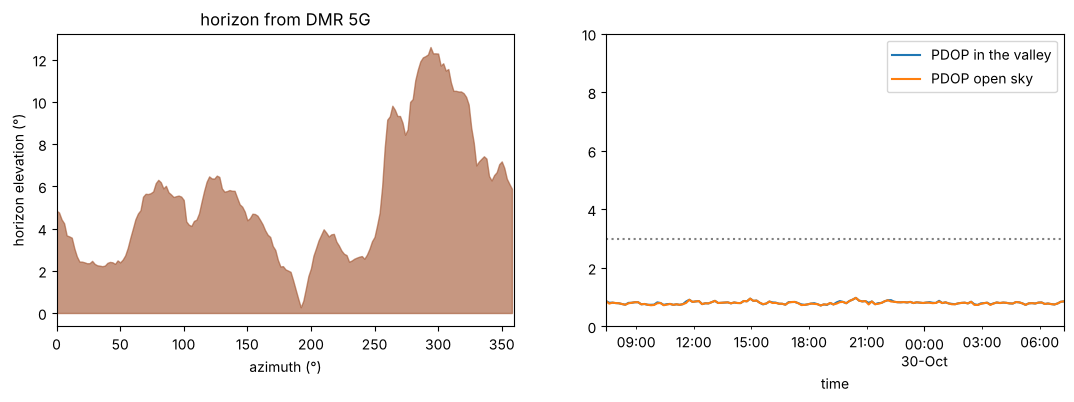

in the valley PDOP < 3 with at least 10 satellites for 24.0 h out of 24 h


In [6]:
VLAT, VLON = 50.1588, 14.3985        # ◀ parameter: point in the valley (by the Vltava in Roztoky)
R_h = 2500
to_sjtsk = Transformer.from_crs(4326, 5514, always_xy=True)
vx, vy = to_sjtsk.transform(VLON, VLAT)
dem, tr = cuzk_raster("dmr5g", vx - R_h, vy - R_h, vx + R_h, vy + R_h, res=10)
row0, col0 = rasterio.transform.rowcol(tr, vx, vy); z0 = dem[row0, col0] + 1.8      # antenna 1.8 m above ground
azs = np.arange(0, 360, 2); dist = np.arange(20, R_h, 10)
hor = []
for a in np.radians(azs):
    xs, ys = vx + dist * np.sin(a), vy + dist * np.cos(a)
    rr, cc = rasterio.transform.rowcol(tr, xs, ys)
    hor.append(np.degrees(np.arctan2(dem[np.array(rr), np.array(cc)] - z0, dist)).max())
hor = np.maximum(np.array(hor), 0)
valley = lambda az: np.maximum(np.interp(az, azs, hor, period=360), mask)
print(f"terrain at the point {dem[row0, col0]:.1f} m a.s.l.; horizon {hor.min():.1f}–{hor.max():.1f}°")
v_day = day_series(valley, lat=VLAT, lon=VLON, step=10)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].fill_between(azs, 0, hor, color="sienna", alpha=0.6); ax[0].set(xlabel="azimuth (°)", ylabel="horizon elevation (°)", xlim=(0, 360), title="horizon from DMR 5G")
v_day.PDOP.plot(ax=ax[1], label="PDOP in the valley"); open_sky.PDOP.plot(ax=ax[1], label="PDOP open sky"); ax[1].axhline(3, color="gray", ls=":")
ax[1].set_ylim(0, 10); ax[1].legend(); plt.show()
good = v_day[(v_day.PDOP < 3) & (v_day.satellites >= 10)]
print(f"in the valley PDOP < 3 with at least 10 satellites for {len(good) * 10 / 60:.1f} h out of 24 h")

> **✏️ Task 3.** Which directions does the valley block most and why? How high does the horizon reach, and is the valley really “deep” for a four-system GNSS receiver? Try `mask = 20` or a point below a rock face. When in the next 24 hours would you survey ground control points in the valley? Why does the terrain model not capture everything that actually blocks or reflects the signal (trees, buildings, rock faces)?

*Your answer:* 

## 5. CZEPOS reference stations

RTK accuracy decreases with distance from the reference station because ionospheric, tropospheric and orbit effects decorrelate. Manufacturers usually state accuracy as 1 cm + 1 ppm (1 mm per km).

In [7]:
q = requests.get("https://ags.cuzk.cz/arcgis/rest/services/BodovaPole/MapServer/0/query",
                 params={"where": "1=1", "outFields": "NAZEV_BODU,B,L,HEL,NAZEV_KU", "returnGeometry": "false", "f": "json"}, timeout=60).json()
cz = pd.DataFrame([f["attributes"] for f in q["features"]])
cz["km"] = 6371 * 2 * np.arcsin(np.sqrt(np.sin(np.radians(cz.B - LAT) / 2) ** 2 + np.cos(np.radians(LAT)) * np.cos(np.radians(cz.B)) * np.sin(np.radians(cz.L - LON) / 2) ** 2))
cz["RTK horiz. (mm)"] = 10 + 1.0 * cz.km
print(f"CZEPOS stations: {len(cz)}")
cz.sort_values("km").head(5).round(2)

CZEPOS stations: 29


,NAZEV_BODU,B,L,HEL,NAZEV_KU,km,RTK horiz. (mm)
16,CPRG,50.13,14.46,356.02,Kobylisy,5.94,15.94
24,GOPE,49.91,14.79,592.60,Ondřejov u Prahy,38.05,48.05
18,CRAK,50.10,13.73,381.87,Rakovník,46.00,56.00
12,CLIT,50.54,14.14,243.28,Litoměřice,48.52,58.52
13,CMBO,50.41,14.91,303.46,Mladá Boleslav,49.24,59.24


## 6. Ellipsoidal height or Bpv?

RTK gives height above the GRS80 ellipsoid (ETRS89). Maps and projects in Czechia use normal height in Bpv. The difference is the height anomaly ζ = h − H. We take densification survey points nearby that have both heights.

points: 45, ζ = 44.461 to 45.367 m, mean 44.906 m


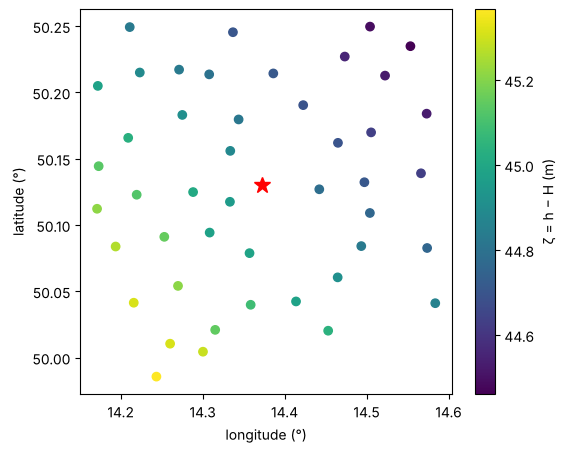

In [8]:
px, py = to_sjtsk.transform(LON, LAT)
half = 15000                       # ◀ parameter: half-width of the surroundings (m)
q = requests.get("https://ags.cuzk.cz/arcgis/rest/services/BodovaPole/MapServer/2/query",
                 params={"geometry": f"{px - half},{py - half},{px + half},{py + half}", "geometryType": "esriGeometryEnvelope", "inSR": 5514,
                         "outFields": "CISLO_SMO5,CISLO,Y,X,VYSKA,B,L,HEL,NAZEV_KU", "returnGeometry": "false", "f": "json"}, timeout=60).json()
pts = pd.DataFrame([f["attributes"] for f in q["features"]])
pts["H_Bpv"] = pd.to_numeric(pts.VYSKA, errors="coerce")
pts = pts.dropna(subset=["H_Bpv", "HEL"])
pts["zeta"] = pts.HEL - pts.H_Bpv
print(f"points: {len(pts)}, ζ = {pts.zeta.min():.3f} to {pts.zeta.max():.3f} m, mean {pts.zeta.mean():.3f} m")
fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(pts.L, pts.B, c=pts.zeta, cmap="viridis"); fig.colorbar(sc, label="ζ = h − H (m)")
ax.plot(LON, LAT, "r*", ms=12); ax.set(xlabel="longitude (°)", ylabel="latitude (°)"); plt.show()

> **✏️ Task 4.** What is the height anomaly around Suchdol and how much does it change over 30 km? What happens to a terrain model or to ground control points if you store RTK heights as Bpv without conversion? Why is subtracting one constant for the whole country not enough, and what should you use (quasigeoid model, ČÚZK transformation service)? How far is the nearest CZEPOS station and what RTK error do you expect from that?

*Your answer:* 

---
### Data sources and references

- Orbital elements: CelesTrak (T. S. Kelso), GNSS group, https://celestrak.org/NORAD/elements/gp.php?GROUP=gnss. Note: TLE with the SGP4 model give satellite positions with errors of the order of kilometres; that is enough for DOP planning, not for computing a receiver position (which uses broadcast ephemerides).
- Survey control and CZEPOS stations: © ČÚZK, service https://ags.cuzk.cz/arcgis/rest/services/BodovaPole/MapServer (CC BY 4.0).
- DMR 5G: © ČÚZK, CC BY 4.0, https://ags.cuzk.cz/arcgis2/rest/services/dmr5g/ImageServer
- Vallado, D. A., Crawford, P., Hujsak, R., Kelso, T. S. (2006). Revisiting Spacetrack Report #3. AIAA 2006-6753 (SGP4 model, `sgp4` library).
- Hofmann-Wellenhof, B., Lichtenegger, H., Wasle, E. (2008). *GNSS – Global Navigation Satellite Systems*. Springer (DOP, multi-GNSS, RTK).

### How to cite

OpenSkyLab (2026). GNSS under the sky: real satellites, DOP, terrain and Bpv heights [notebook, teaching resource], version 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/gnss_sky_en.ipynb. Licence CC BY 4.0.

Notebook text and code: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data are under their providers' licences (see above).

*This resource was developed by the OpenSkyLab team with the assistance of the generative AI Claude (Anthropic), used for drafting code and text. The authors are responsible for the content.*